In [8]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
from tensorflow import keras

plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

2026-11-04 16:26:59.771591: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
!python implant_stamps_add_or_mult.py selftest --image "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020148032_000686_zg_c05_x_0002.fits.fz"

1) mult/renorm vs legacy: maxcol equal = True | max abs diff = 0.0 (should be ~1e-12)
2) injected flux, same A, no renorm:
   peak pixel delta   mult 0.3886   add 0.3805
   summed delta       mult 13.31   add 13.3
   (these should be comparable; the matching is on the mean, so not identical)
3) dimming A=0.5: min delta mult -0.3886  add -0.3805 | pixels pushed below image min: mult 0  add 0
3) dimming A=0.9: min delta mult -0.07772  add -0.07611 | pixels pushed below image min: mult 0  add 0


In [20]:
save_name='offset_sat_newhparam_b50_allstamps_satdumbsplit_folds'

In [15]:
root = "/lustre/lrspec/ZTF_data/nov2026/training_add_renorm/"

In [46]:
/lustre/lrspec/ZTF_data/nov2026/training_add_renorm/CNN

NameError: name 'lustre' is not defined

In [45]:
os.path.join(root,"CNN")

'/lustre/lrspec/ZTF_data/nov2026/training_add_renorm/CNN'

In [21]:
lil_save_name = "additive_renorm"

In [19]:
feat_te = np.load(os.path.join(root,"saved_loss/feat_te_"+"additive_renorm.npy"))


In [22]:
for fold in range(0,5):
    model = keras.models.load_model("/lustre/lrspec/ZTF_data/CNN/CNN_"+save_name+'_'+str(fold))
    label_pred_te = model.predict(feat_te)
    np.save(root+"saved_loss/label_pred_te_"+lil_save_name+"_fold_"+str(fold), label_pred_te)

2448/2448 [==============================] - 3s 1ms/step


In [24]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [27]:
%matplotlib inline

loading data


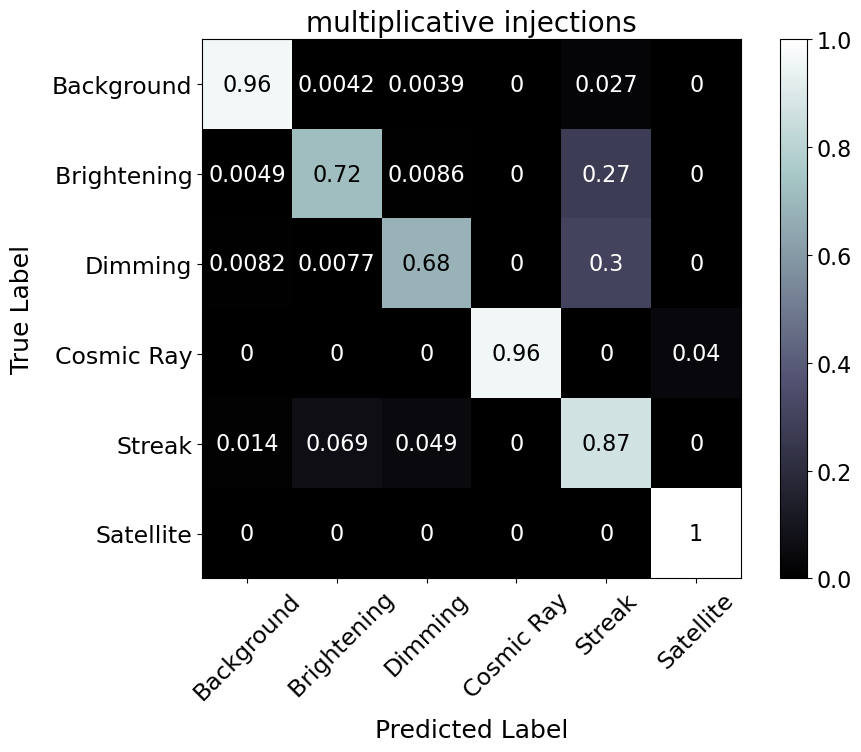

In [32]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title="multiplicative injections", absolute=False, root='/lustre/lrspec/ZTF_data/')

loading data


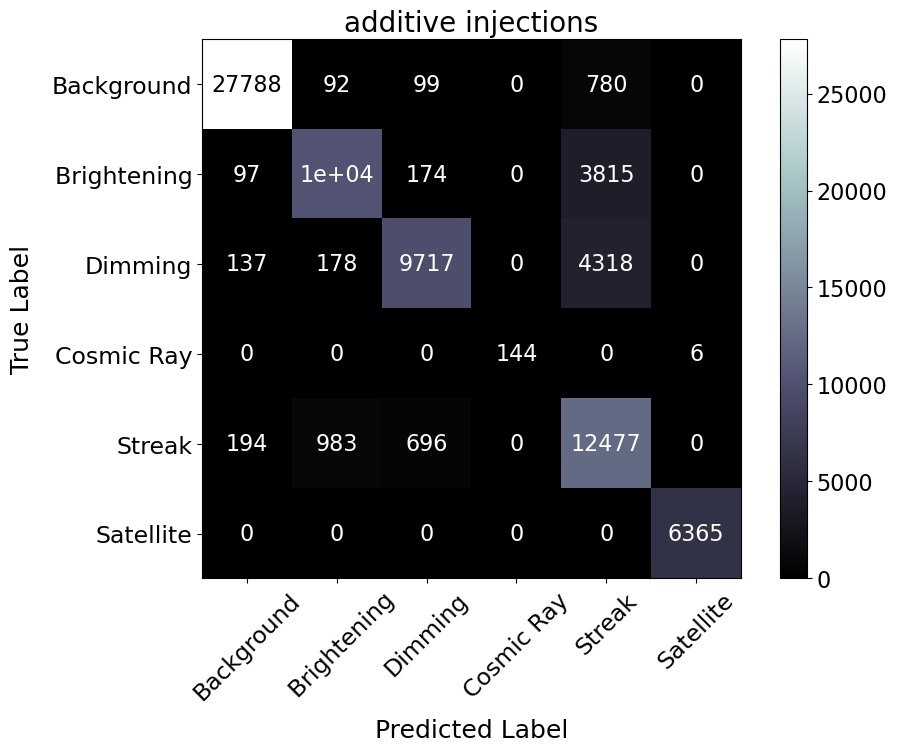

In [33]:
rff.show_confusion_matrix(lil_save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title="additive injections", absolute=True, root=root)

In [36]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [38]:
%matplotlib inline

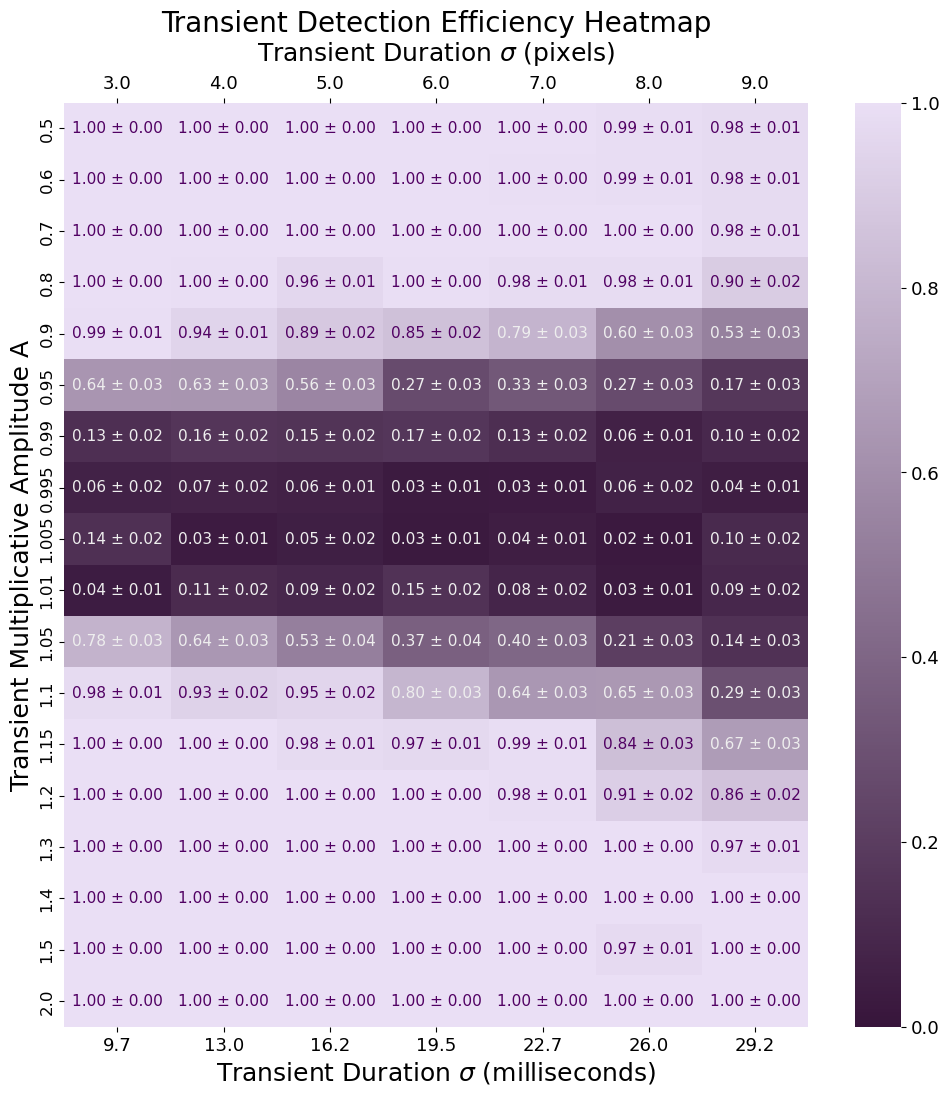

In [42]:
rff.heatmap(lil_save_name, folds=True, color1='#EADFF5', color2='#37153B',tlight='#EEEEEE', tdark='#510163', root=root)

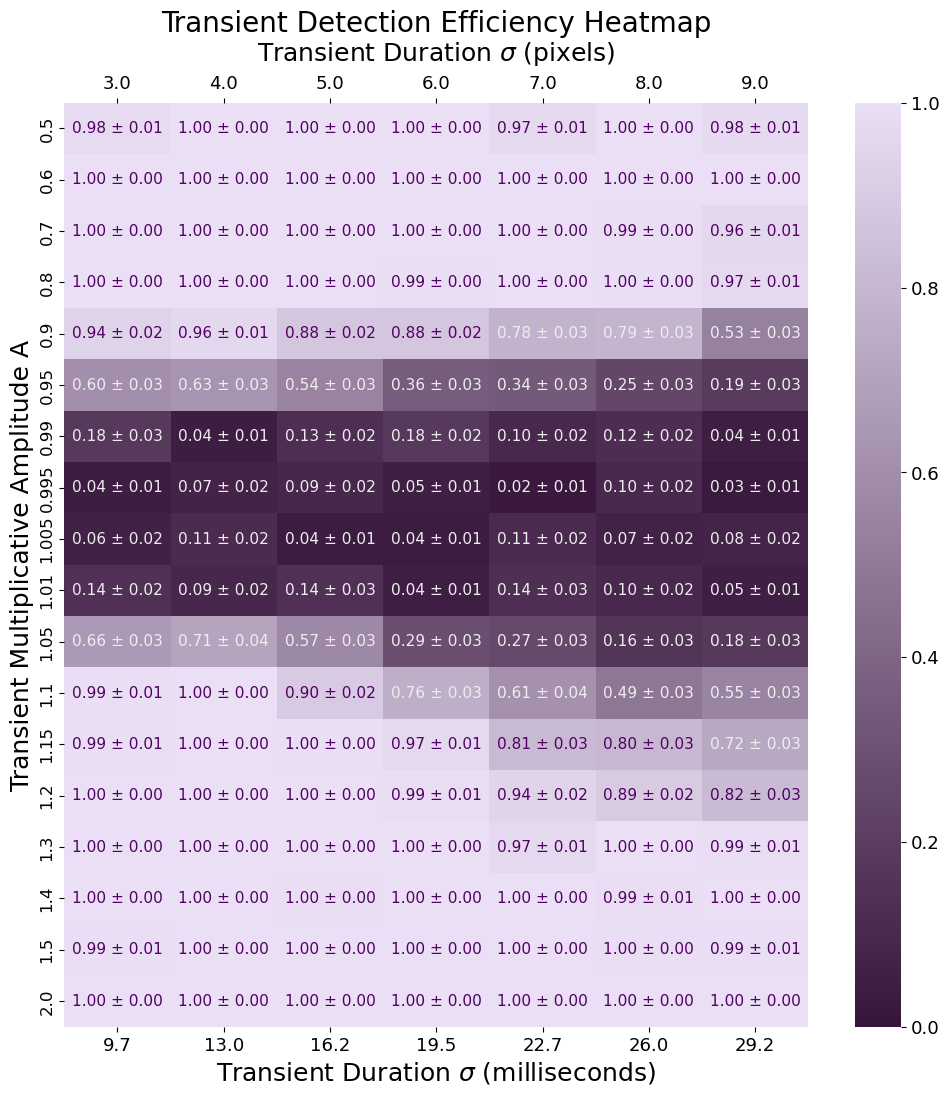

In [41]:
rff.heatmap(save_name, folds=True, color1='#EADFF5', color2='#37153B',tlight='#EEEEEE', tdark='#510163')

In [47]:
def minmax_per_stamp(stamps, eps=1e-12):
    stamps = stamps.astype(np.float32)
    axes = tuple(range(1, stamps.ndim))          # all axes except the batch axis
    mn = stamps.min(axis=axes, keepdims=True)
    mx = stamps.max(axis=axes, keepdims=True)
    return (stamps - mn) / np.maximum(mx - mn, eps)

In [49]:
bg_train = np.array([[1,2,3],[3,2,1],[1,1,1]])

In [51]:
pos_train = np.array([[.1,.2,.3],[.3,.2,.1],[.1,.1,.1]])

In [52]:
stamps = np.concatenate([bg_train, pos_train], axis=0)

In [56]:
norm_stamp="True"

In [57]:
if norm_stamp=="True" or norm_stamp==True:
    print("hey")

hey


In [62]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DEFAULT_ROOT = '/lustre/lrspec/ZTF_data/'

def load_points(save_name, folds=False, root=DEFAULT_ROOT):
    """Returns (bness, lens, correct_bool). Files are read from root + 'saved_loss/'."""
    p = root.rstrip('/') + "/saved_loss/"
    bness = np.load(f"{p}our_bness_te_{save_name}.npy")
    lens  = np.load(f"{p}our_lens_te_{save_name}.npy")
    targ  = np.load(f"{p}our_targ_te_{save_name}.npy")
    if not folds:
        pred = np.load(f"{p}our_pred_te_max_{save_name}.npy")
    else:
        preds = [np.load(f"{p}label_pred_te_{save_name}_fold_{f}.npy") for f in range(5)]
        label_pred = np.mean(preds, axis=0)
        targ_te = np.load(f"{p}targ_te_{save_name}.npy")
        mask = (targ_te == 1) | (targ_te == 2)
        pred = np.argmax(label_pred[mask], axis=1)
    return bness, lens, (targ == pred)


def make_bins(values, pad):
    return np.concatenate([[values[0] - pad],
                           (values[:-1] + values[1:]) / 2,
                           [values[-1] + pad]])


def efficiency_grid(bness, lens, correct, b_vals, l_vals):
    b_bins, l_bins = make_bins(b_vals, 0.1), make_bins(l_vals, 0.5)
    correct_hist, _, _ = np.histogram2d(bness[correct], lens[correct], bins=[b_bins, l_bins])
    total_hist, _, _   = np.histogram2d(bness, lens, bins=[b_bins, l_bins])
    with np.errstate(divide='ignore', invalid='ignore'):
        eff = correct_hist / total_hist
        err = np.sqrt(eff * (1 - eff) / total_hist)
    return eff, err, total_hist


def plot_grid(grid, b_vals, l_vals, err=None, cmap='RdBu', vmin=0, vmax=1,
              title="", cbar_label="", flip_text_at=None):
    plt.figure(figsize=(12, 12))
    ax = sns.heatmap(grid, cmap=cmap, vmin=vmin, vmax=vmax,
                     xticklabels=[f"{v:.1f}" for v in np.arange(3, len(l_vals) + 3) * 10000 / 3080],
                     yticklabels=b_vals, cbar_kws={'label': cbar_label})
    ax.set_xlabel(r"Transient Duration $\sigma$ (milliseconds)", fontsize=18)
    ax.set_ylabel("Transient Multiplicative Amplitude A", fontsize=18)
    ax.set_title(title, fontsize=20)

    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    ax_top.set_xticks(np.arange(len(l_vals)) + 0.5)
    ax_top.set_xticklabels(l_vals, fontsize=13)
    ax_top.set_xlabel(r"Transient Duration $\sigma$ (pixels)", fontsize=18, labelpad=10)

    if err is not None:
        for i in range(grid.shape[0]):
            for j in range(grid.shape[1]):
                if np.isfinite(grid[i, j]):
                    dark = flip_text_at is None or abs(grid[i, j]) < flip_text_at
                    ax.text(j + 0.5, i + 0.5, f"{grid[i, j]:+.2f} ± {err[i, j]:.2f}",
                            ha="center", va="center", fontsize=11,
                            color="black" if dark else "white")
    for a in (ax, ax_top):
        for s in a.spines.values():
            s.set_visible(False)
    return ax


def diff_heatmap(name_a, name_b, folds_a=False, folds_b=False,
                 root=DEFAULT_ROOT, root_a=None, root_b=None,
                 cmap='RdBu', vmin=-1, vmax=1):
    """
    root   : default root used for both runs
    root_a : override root for run A (falls back to `root`)
    root_b : override root for run B (falls back to `root`)
    """
    root_a = root if root_a is None else root_a
    root_b = root if root_b is None else root_b

    ba, la, ca = load_points(name_a, folds_a, root=root_a)
    bb, lb, cb = load_points(name_b, folds_b, root=root_b)

    # shared grid from the union of both runs
    b_vals = np.unique(np.concatenate([ba, bb]))
    l_vals = np.unique(np.concatenate([la, lb]))

    eff_a, err_a, _ = efficiency_grid(ba, la, ca, b_vals, l_vals)
    eff_b, err_b, _ = efficiency_grid(bb, lb, cb, b_vals, l_vals)

    diff = eff_a - eff_b                      # NaN if either cell is empty
    diff_err = np.sqrt(err_a**2 + err_b**2)   # assumes independent runs

    plot_grid(diff, b_vals, l_vals, err=diff_err, cmap=cmap, vmin=vmin, vmax=vmax,
              title=f"Efficiency difference: {name_a} − {name_b}",
              cbar_label="Δ efficiency", flip_text_at=0.6)
    return diff, diff_err

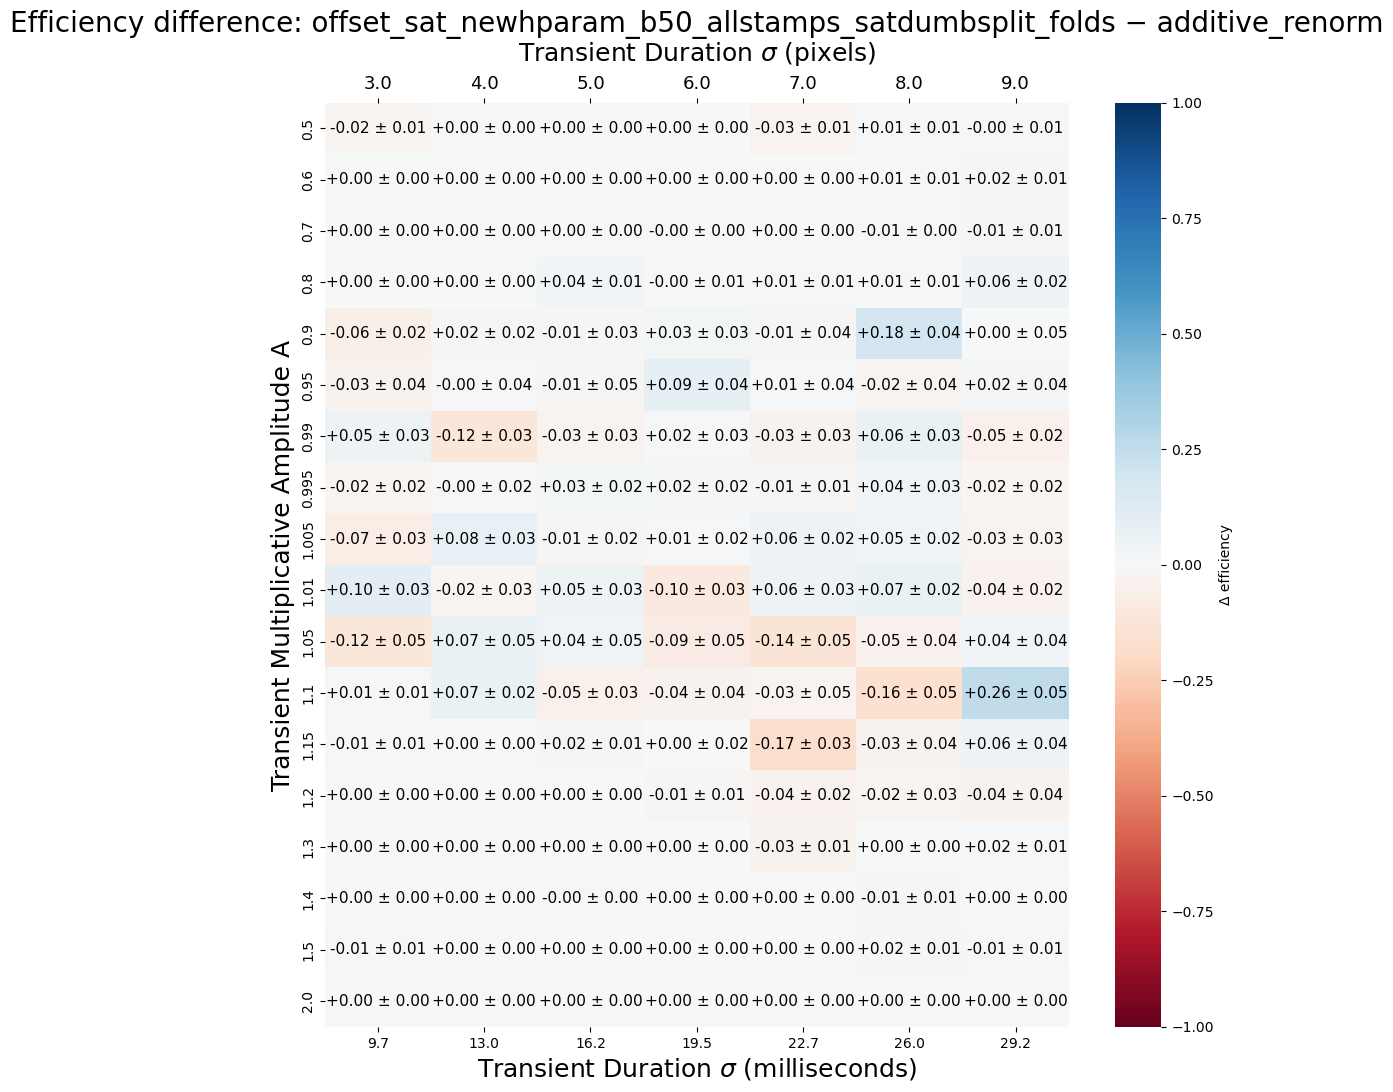

In [63]:

diff, err = diff_heatmap(save_name, lil_save_name, 
                         folds_a=True, folds_b=True ,
                         root_a="/lustre/lrspec/ZTF_data/",
                         root_b=root)

In [107]:
#checking dimming to zero
!python make_dim_to_zero.py --mode mult --norm renorm --out /lustre/lrspec/ZTF_data/dim0_mult_renorm/ --n-images 40

ztf_20221020138241_000686_zi_c01_x_0007.fits.fz hdu 1 -> 50 stamps
ztf_20221017148750_000831_zi_c03_x_0028.fits.fz hdu 3 -> 50 stamps
ztf_20221014162894_000802_zg_c03_x_0010.fits.fz hdu 4 -> 50 stamps
ztf_20220820237546_000798_zr_c12_x_0001.fits.fz hdu 3 -> 50 stamps
ztf_20221017148750_000831_zi_c04_x_0005.fits.fz hdu 2 -> 50 stamps
ztf_20221020138241_000686_zi_c08_x_0024.fits.fz hdu 1 -> 50 stamps
ztf_20221020138241_000686_zi_c01_x_0010.fits.fz hdu 3 -> 50 stamps
ztf_20220820237546_000798_zr_c12_x_0000.fits.fz hdu 2 -> 50 stamps
ztf_20221020138241_000686_zi_c08_x_0007.fits.fz hdu 1 -> 50 stamps
ztf_20221017148750_000831_zi_c01_x_0009.fits.fz hdu 4 -> 50 stamps
ztf_20221014162894_000802_zg_c01_x_0015.fits.fz hdu 1 -> 50 stamps
ztf_20221014162894_000802_zg_c03_x_0012.fits.fz hdu 3 -> 50 stamps
ztf_20220820237546_000798_zr_c07_x_0004.fits.fz hdu 3 -> 50 stamps
ztf_20220820237546_000798_zr_c07_x_0003.fits.fz hdu 3 -> 50 stamps
ztf_20221020138241_000686_zi_c01_x_0013.fits.fz hdu 2 -> 50 st

In [78]:
!ls /lustre/lrspec/ZTF_data/dim0_mult_renorm/images

ztf_20220820237546_000798_zr_c12_x_0001._3_stamps_dim0.npy
ztf_20221014162894_000802_zg_c01_x_0012._2_stamps_dim0.npy
ztf_20221014162894_000802_zg_c01_x_0017._2_stamps_dim0.npy
ztf_20221017148750_000831_zi_c05_x_0001._2_stamps_dim0.npy


In [110]:
all_feat_te = []
all_info_te = []
for filename in os.listdir("/lustre/lrspec/ZTF_data/dim0_mult_renorm/images"):
    print(filename)
    feat_te = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/images", filename))
    info_te = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/info", filename[:-4]+"_info.npy"))
    all_feat_te.append(feat_te)
    all_info_te.append(info_te)
                      
                      

ztf_20221017148750_000831_zi_c04_x_0005._2_stamps_dim0.npy
ztf_20221017148750_000831_zi_c05_x_0001._2_stamps_dim0.npy
ztf_20221014162894_000802_zg_c01_x_0012._2_stamps_dim0.npy
ztf_20221017148750_000831_zi_c01_x_0024._3_stamps_dim0.npy
ztf_20220820237546_000798_zr_c10_x_0001._1_stamps_dim0.npy
ztf_20221020138241_000686_zi_c01_x_0008._3_stamps_dim0.npy
ztf_20221020138241_000686_zi_c05_x_0007._3_stamps_dim0.npy
ztf_20220820237546_000798_zr_c12_x_0000._2_stamps_dim0.npy
ztf_20221014162894_000802_zg_c01_x_0022._1_stamps_dim0.npy
ztf_20221017148750_000831_zi_c03_x_0020._2_stamps_dim0.npy
ztf_20221020138241_000686_zi_c05_x_0006._4_stamps_dim0.npy
ztf_20221020138241_000686_zi_c01_x_0017._2_stamps_dim0.npy
ztf_20221020138241_000686_zi_c01_x_0010._3_stamps_dim0.npy
ztf_20221014162894_000802_zg_c03_x_0010._4_stamps_dim0.npy
ztf_20221014162894_000802_zg_c01_x_0010._1_stamps_dim0.npy
ztf_20221014162894_000802_zg_c01_x_0015._1_stamps_dim0.npy
ztf_20221014162894_000802_zg_c01_x_0017._2_stamps_dim0.n

In [126]:
np.shape(all_info_te)

(43, 50, 5)

In [123]:
reshaped = np.reshape(all_feat_te, (43*50, 20, 20))

In [127]:
reshaped_info = np.reshape(all_info_te, (43*50, 5))

In [124]:
np.shape(reshaped)

(2150, 20, 20)

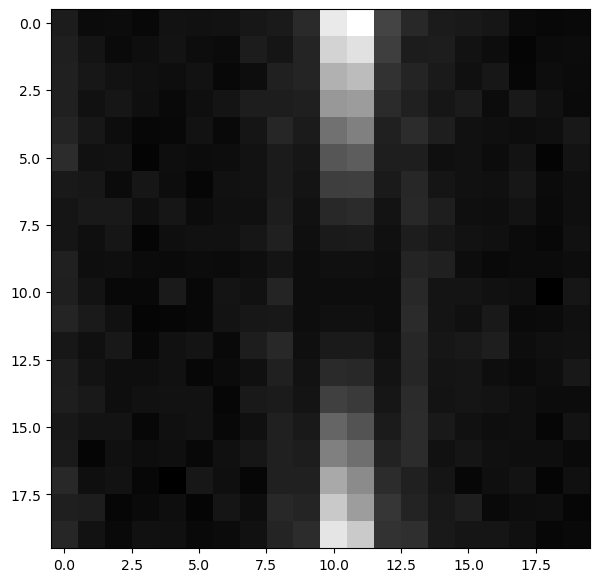

In [125]:
plt.imshow(reshaped[0])

In [79]:
feat_te = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/images", 
                               "ztf_20220820237546_000798_zr_c12_x_0001._3_stamps_dim0.npy"))


In [80]:
feat_te1 = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/images", 
                               "ztf_20221014162894_000802_zg_c01_x_0012._2_stamps_dim0.npy"))


In [81]:
feat_te2 = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/images", 
                               "ztf_20221014162894_000802_zg_c01_x_0017._2_stamps_dim0.npy"))


In [82]:
feat_te3 = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/images", 
                               "ztf_20221017148750_000831_zi_c05_x_0001._2_stamps_dim0.npy"))


In [91]:
!ls /lustre/lrspec/ZTF_data/dim0_mult_renorm/info

ztf_20220820237546_000798_zr_c12_x_0001._3_stamps_dim0_info.npy
ztf_20221014162894_000802_zg_c01_x_0012._2_stamps_dim0_info.npy
ztf_20221014162894_000802_zg_c01_x_0017._2_stamps_dim0_info.npy
ztf_20221017148750_000831_zi_c05_x_0001._2_stamps_dim0_info.npy


In [92]:
info_te = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/info", 
                               "ztf_20220820237546_000798_zr_c12_x_0001._3_stamps_dim0_info.npy"))


In [94]:
info_te1 = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/info", 
                               "ztf_20221014162894_000802_zg_c01_x_0012._2_stamps_dim0_info.npy"))


In [93]:
info_te2 = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/info", 
                               "ztf_20221014162894_000802_zg_c01_x_0017._2_stamps_dim0_info.npy"))
info_te3 = np.load(os.path.join("/lustre/lrspec/ZTF_data/dim0_mult_renorm/info", 
                               "ztf_20221017148750_000831_zi_c05_x_0001._2_stamps_dim0_info.npy"))


In [95]:
info_te_all = np.concatenate((info_te, info_te1,info_te2,info_te3), axis=0)

In [83]:
feat_te_all = np.concatenate((feat_te, feat_te1,feat_te2,feat_te3), axis=0)

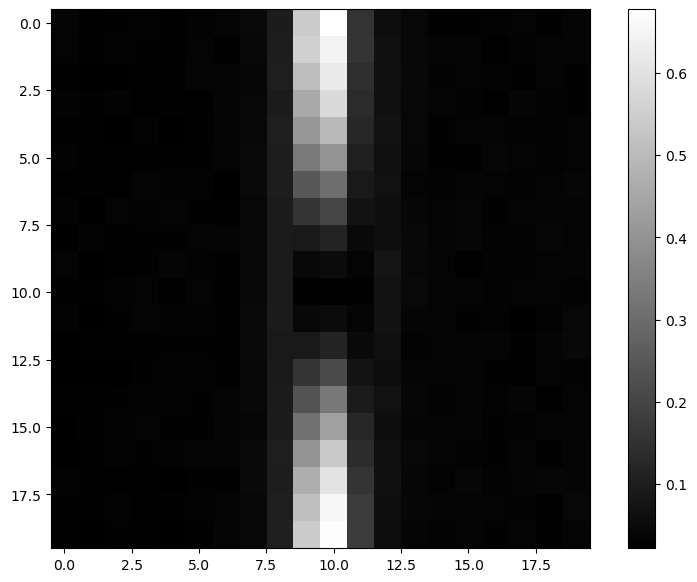

In [86]:
plt.imshow(feat_te_all[10])
plt.colorbar()

In [128]:
new_save_name = 'dim0_mult_renorm'
label_pred_te_all = []
for fold in range(0,5):
    # label_pred_te_onefold = []
    model = keras.models.load_model("/lustre/lrspec/ZTF_data/CNN/CNN_"+save_name+'_'+str(fold))
    label_pred_te = model.predict(reshaped)
    # label_pred_te_onefold.append(label_pred_te)
    label_pred_te_all.append(label_pred_te)
    # np.save(root+"saved_loss/label_pred_te_"+new_save_name+"_fold_"+str(fold), label_pred_te)

68/68 [==============================] - 0s 1ms/step


In [129]:
averaged_preds = np.average(label_pred_te_all, axis=0)

(array([  79.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
        2071.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

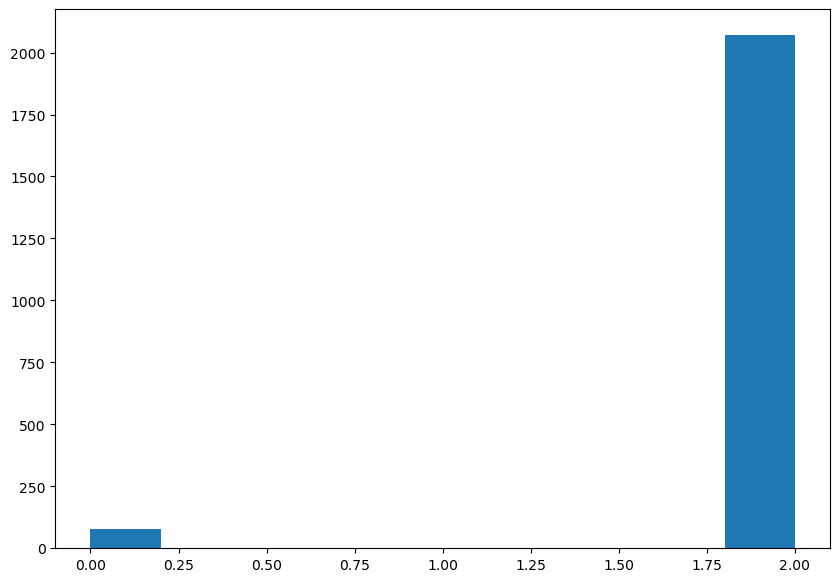

In [130]:
plt.hist(np.argmax(averaged_preds, axis=1))

In [131]:
info_df = pd.DataFrame(reshaped_info)

In [132]:
info_df['label']=np.argmax(averaged_preds, axis=1)

In [143]:
subset = info_df[info_df[4]!=-2]

In [144]:
subset = subset[subset[4]!=2]

In [134]:
np.sum(subset['label']==2)/np.sum(subset['label']==0)

9.909090909090908

In [138]:
np.sum(info_df['label']==2)/(len(info_df))

0.9632558139534884

Text(0.5, 0, 'duration')

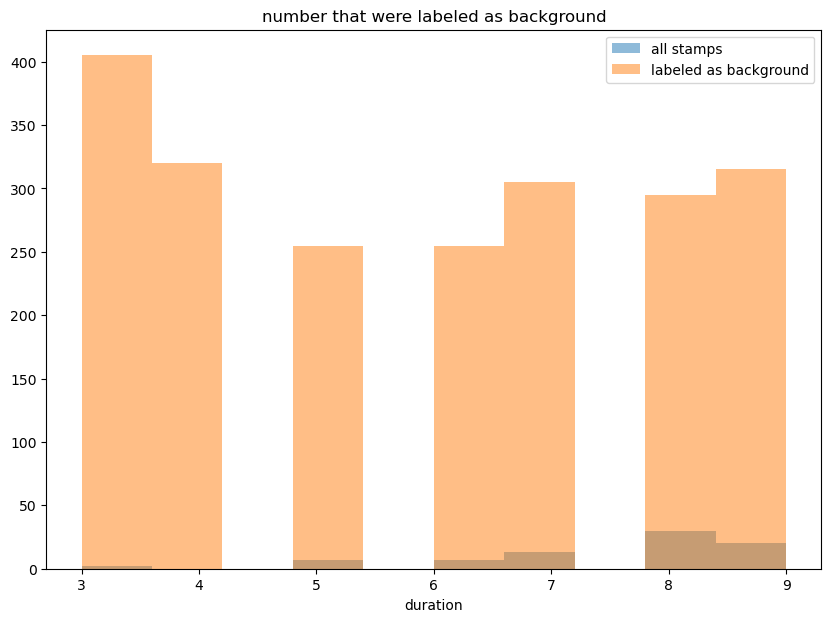

In [150]:
plt.hist(info_df[info_df['label']==0][1], alpha=.5, label="all stamps")
plt.hist(info_df[1], alpha=.5, label="labeled as background")
plt.legend()
plt.title("number that were labeled as background")
plt.xlabel("duration")

In [146]:
info_df

,0,1,2,3,4,label
0,0.0,8.0,378.0,837.0,0.0,2
1,0.0,8.0,378.0,837.0,1.0,2
2,0.0,8.0,378.0,837.0,2.0,2
3,0.0,8.0,378.0,837.0,-1.0,2
4,0.0,8.0,378.0,837.0,-2.0,2
...,...,...,...,...,...,...
2145,0.0,6.0,2565.0,388.0,0.0,2
2146,0.0,6.0,2565.0,388.0,1.0,2
2147,0.0,6.0,2565.0,388.0,2.0,2
2148,0.0,6.0,2565.0,388.0,-1.0,2


Text(0.5, 0, 'duration')

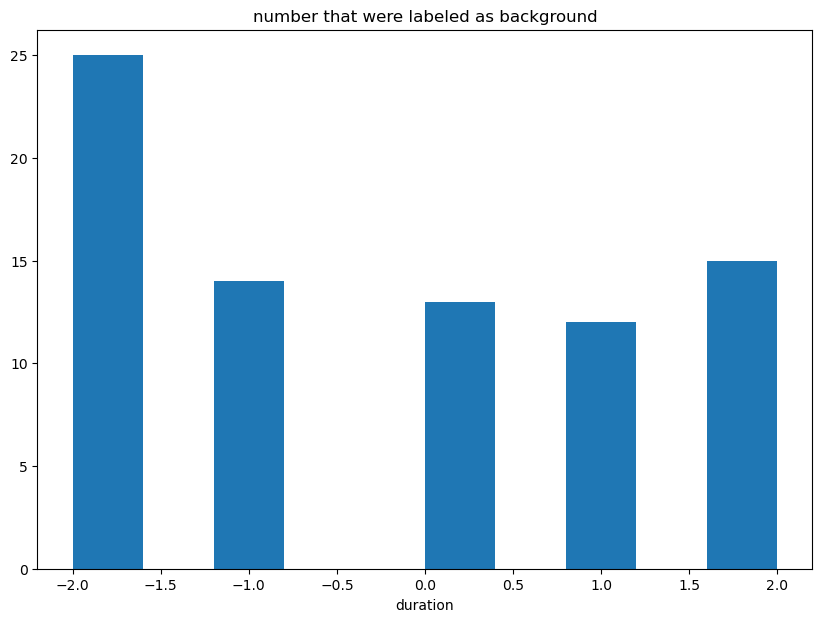

In [147]:
plt.hist(info_df[info_df['label']==0][4])
plt.title("number that were labeled as background")
plt.xlabel("duration")

In [151]:
fpath_sat = "/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/"

image_path = fpath_sat + "images/"
info_path = fpath_sat + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    # file_idx = np.full((infos_arr.shape[0], 1), i)
    # infos_arr[0]=file_idx # = np.concatenate([file_idx, infos_arr], axis=1)
    file_idx = np.arange(0, len(infos_arr))
    infos_arr[:,0]=file_idx
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_sat_stamps = trans_arr
        all_sat_stamps_info = infos_arr
    else:
        all_sat_stamps = np.concatenate((all_sat_stamps, trans_arr), axis=0).astype('int')
        all_sat_stamps_info = np.concatenate((all_sat_stamps_info, infos_arr), axis=0).astype('int')


sat_stamps.npy
(25460, 20, 20)
(25460, 6)


In [159]:
!ls /lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/images

sat_stamps.npy


In [157]:
all_sat_stamps.shape

(25460, 20, 20)

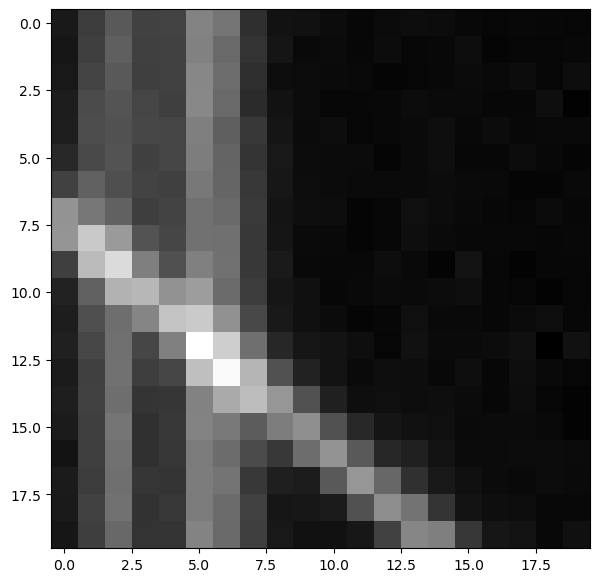

In [158]:
plt.imshow(all_sat_stamps[10000])